# 2010 — Weight Initialization (Glorot/Xavier and He)

**Papers:** Xavier Glorot & Yoshua Bengio, *"Understanding the difficulty of training deep feedforward neural networks"*, AISTATS (2010); Kaiming He, Xiangyu Zhang, Shaoqing Ren & Jian Sun, *"Delving Deep into Rectifiers"*, ICCV (2015). Earlier: LeCun, Bottou, Orr & Müller, *"Efficient BackProp"* (1998).

Before 2006 deep networks were thought to be nearly untrainable, and layer-wise pretraining (notebook 15) was the workaround. Glorot & Bengio showed that much of the problem was simply **the scale of the random initial weights**.

Each layer computes $y = Wx$. If the weights have variance $\sigma^2$ and $x$ has $n_{in}$ inputs of variance $v$, then $\operatorname{Var}(y) = n_{in}\sigma^2 v$. Across $L$ layers the signal is multiplied by $(n_{in}\sigma^2)^L$: it **explodes or vanishes exponentially** unless $n_{in}\sigma^2 \approx 1$. The gradients flowing back obey the same rule with $n_{out}$.

- **Xavier/Glorot** (for tanh, roughly linear near 0): $\sigma^2 = \dfrac{2}{n_{in} + n_{out}}$, a compromise between the forward and the backward condition.
- **He/Kaiming** (for ReLU, which zeroes half its inputs and halves the variance): $\sigma^2 = \dfrac{2}{n_{in}}$.

![Diagram: Weight initialization (Glorot & Bengio, 2010; He et al., 2015)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/16_2010_weight_initialization.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
def make_mlp(depth, width, act, init, d_in=64, d_out=10):
    layers, dims = [], [d_in] + [width] * depth
    for a, b in zip(dims[:-1], dims[1:]):
        lin = nn.Linear(a, b)
        std = {"N(0, 1)": 1.0, "N(0, 0.01²)": 0.01, "Xavier": math.sqrt(2 / (a + b)), "He": math.sqrt(2 / a)}[init]
        nn.init.normal_(lin.weight, 0, std); nn.init.zeros_(lin.bias)
        layers += [lin, nn.Tanh() if act == "tanh" else nn.ReLU()]
    layers.append(nn.Linear(width, d_out))
    return nn.Sequential(*layers)

## Forward signal and backward gradient, layer by layer
A 50-layer, 256-wide network at initialisation, no training. Left: the standard deviation of each layer's activations on a batch of random inputs. Right: the norm of the gradient that reaches each layer's weights.

tanh N(0, 1)      activation std: layer 1 9.48e-01 → layer 50 9.74e-01 | weight-grad norm: layer 1 inf, layer 50 2.88e-02
tanh N(0, 0.01²)  activation std: layer 1 8.29e-02 → layer 50 0.00e+00 | weight-grad norm: layer 1 0.00e+00, layer 50 0.00e+00


tanh Xavier       activation std: layer 1 4.88e-01 → layer 50 8.31e-02 | weight-grad norm: layer 1 2.35e-03, layer 50 9.46e-03
tanh He           activation std: layer 1 7.19e-01 → layer 50 5.50e-01 | weight-grad norm: layer 1 2.40e-01, layer 50 1.52e-01


relu N(0, 1)      activation std: layer 1 5.39e+00 → layer 50 nan | weight-grad norm: layer 1 nan, layer 50 nan
relu N(0, 0.01²)  activation std: layer 1 5.39e-02 → layer 50 0.00e+00 | weight-grad norm: layer 1 0.00e+00, layer 50 0.00e+00


relu Xavier       activation std: layer 1 4.26e-01 → layer 50 1.60e-08 | weight-grad norm: layer 1 1.17e-10, layer 50 3.56e-09
relu He           activation std: layer 1 9.52e-01 → layer 50 8.46e-01 | weight-grad norm: layer 1 2.25e-01, layer 50 3.29e+00


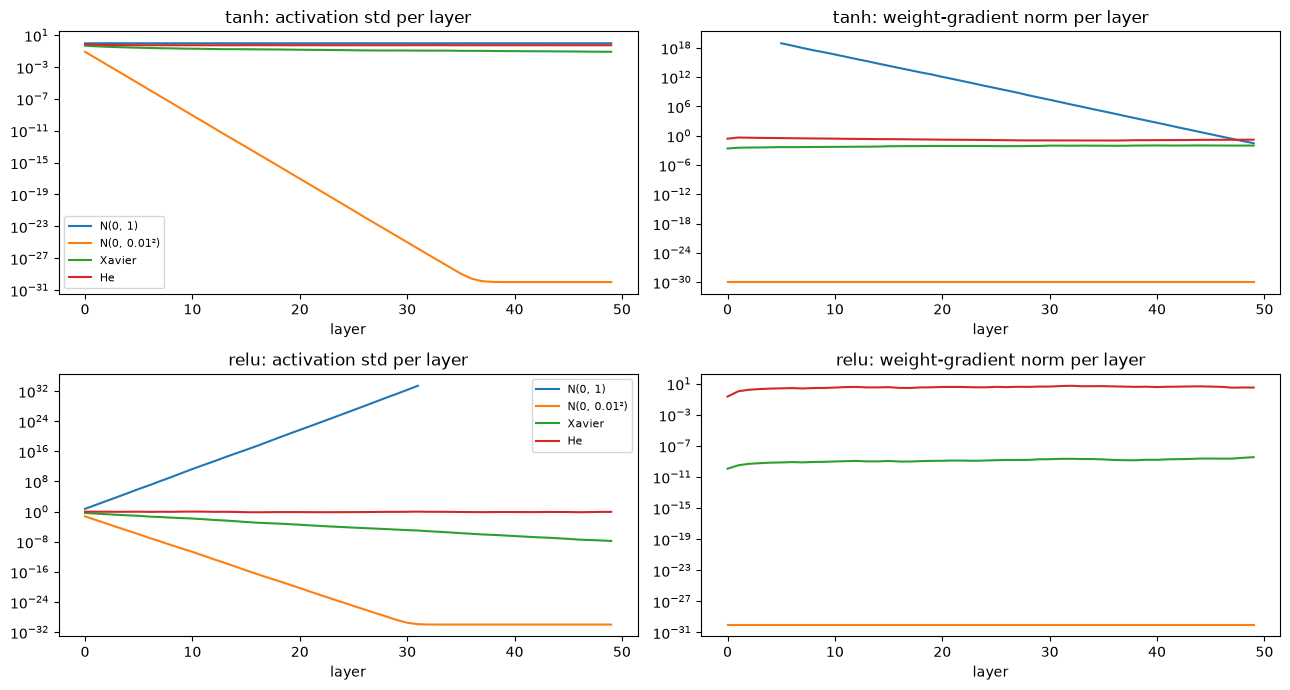

In [3]:
seed_everything(0)
x = torch.randn(512, 64)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for row, act in enumerate(["tanh", "relu"]):
    for init in ["N(0, 1)", "N(0, 0.01²)", "Xavier", "He"]:
        seed_everything(0); net = make_mlp(50, 256, act, init)
        acts, h = [], x
        for m in net:
            h = m(h)
            if isinstance(m, (nn.Tanh, nn.ReLU)): h.retain_grad(); acts.append(h)
        net(x).pow(2).mean().backward()
        stds = [a.std().item() for a in acts]
        grads = [m.weight.grad.norm().item() for m in net if isinstance(m, nn.Linear)][:-1]
        axes[row, 0].semilogy(np.array(stds) + 1e-30, label=init); axes[row, 1].semilogy(np.array(grads) + 1e-30, label=init)
        print(f"{act:4s} {init:12s} activation std: layer 1 {stds[0]:.2e} → layer 50 {stds[-1]:.2e} | weight-grad norm: layer 1 {grads[0]:.2e}, layer 50 {grads[-1]:.2e}")
    axes[row, 0].set(title=f"{act}: activation std per layer", xlabel="layer"); axes[row, 1].set(title=f"{act}: weight-gradient norm per layer", xlabel="layer")
    axes[row, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Read the plots:
- **N(0, 0.01²):** every layer multiplies the signal by $\sqrt{256}\times 0.01 = 0.16$ (a ~6× shrink), so by layer 50 activations and gradients underflow to exactly zero.
- **N(0, 1):** each layer multiplies the signal by $\sqrt{256} = 16$ before the nonlinearity. tanh units saturate at ±1, and the backward pass, which multiplies by $W^\top$ at every layer, explodes to infinity. ReLU has no saturation, so its forward signal itself overflows (`nan`).
- **Xavier** keeps tanh in a usable range, although the signal still decays slowly with depth because tanh's slope is below 1 (PyTorch's `calculate_gain('tanh') = 5/3` compensates for that). For ReLU, Xavier loses a factor of $\sqrt2$ per layer, because ReLU discards half the variance: after 50 layers the signal is ~$10^{-8}$. **He** fixes exactly that factor and keeps ReLU steady.
## Does it matter for training?
A 20-layer plain MLP (no normalization, no residuals) on the 8×8 digits (inputs standardised), SGD with momentum as in Glorot & Bengio, 30 epochs, the same learning rate for every run.

tanh + N(0, 0.01²)  final train loss 2.303   test acc 0.103


tanh + N(0, 1)      final train loss 2.054   test acc 0.208


tanh + Xavier       final train loss 0.003   test acc 0.964


relu + N(0, 0.01²)  final train loss 2.303   test acc 0.103


relu + Xavier       final train loss 1.105   test acc 0.522


relu + He           final train loss 0.001   test acc 0.942


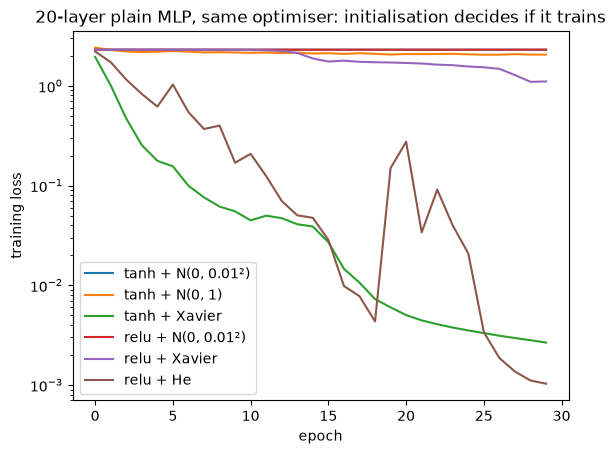

In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.flatten(1).to(device) if t.dim() > 2 else t.to(device) for t in load_digits_tensors()]
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6; Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
def train(act, init, depth=20, epochs=30):
    seed_everything(0); net = make_mlp(depth, 128, act, init).to(device)
    opt = torch.optim.SGD(net.parameters(), lr=0.01, momentum=0.9); losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), device=device); tot = 0
        for i in range(0, len(Xtr), 64):
            idx = perm[i:i + 64]; loss = F.cross_entropy(net(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        losses.append(tot / len(Xtr))
    with torch.no_grad(): acc = (net(Xte).argmax(1) == yte).float().mean().item()
    return losses, acc
runs = {}
for act, init in [("tanh", "N(0, 0.01²)"), ("tanh", "N(0, 1)"), ("tanh", "Xavier"), ("relu", "N(0, 0.01²)"), ("relu", "Xavier"), ("relu", "He")]:
    runs[(act, init)] = train(act, init)
    print(f"{act:4s} + {init:12s} final train loss {runs[(act, init)][0][-1]:.3f}   test acc {runs[(act, init)][1]:.3f}")
for (act, init), (l, _) in runs.items(): plt.plot(l, label=f"{act} + {init}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.title("20-layer plain MLP, same optimiser: initialisation decides if it trains"); plt.legend(); plt.show()

## Takeaways
- **Variance bookkeeping:** keep $n\sigma^2$ (times the activation's gain) equal to 1 per layer, forward and backward. Xavier does this for tanh, He for ReLU (PyTorch's default `nn.Linear` init is a uniform LeCun-style $1/n_{in}$ variant).
- Good initialisation made deep supervised networks trainable from scratch and, together with ReLU and GPUs, helped end the pretraining era (AlexNet, notebook 17).
- Later tools reduced the sensitivity further: batch/layer normalization (notebook 28) re-scale activations during training, and residual connections (notebook 29) make the identity the default. Modern LLMs still choose init scales carefully (e.g. scaling output projections by $1/\sqrt{2L}$ in GPT-2, or μP's width-dependent rules) so the same hyperparameters work across sizes.